<div style="background:linear-gradient(90deg,#0A6E68,#0FB9B1);padding:22px 28px;border-radius:10px;margin:18px 0 10px 0;"><h1 style="color:#ffffff;margin:0;font-weight:normal;">2. Cleaning — raw House 1 → clean 1-minute table</h1></div>

<div style="background:linear-gradient(90deg,#0A6E68,#0FB9B1);padding:22px 28px;border-radius:10px;margin:18px 0 10px 0;"><h2 style="color:#ffffff;margin:0;font-weight:normal;">1. Objective and raw data</h2></div>

**Objective:** a simple, reproducible pipeline that turns the two raw files of House 1 into **one table with one row per minute**.

**Raw data** (full inspection in notebook 1):
- two files, `RAW_House1_Part1.csv` and `RAW_House1_Part2.csv`, with the columns `Time`, `Unix`, `Aggregate` and `Appliance1`–`Appliance9` (power in watts, a reading every few seconds)
- Part 1 uses `0` for an unavailable sensor, Part 2 uses `NaN`
- the two parts overlap for about three months

The raw tables (`raw1`, `raw2`) are **never modified**. Every step works on a copy, and the result is the separate table `clean`.

**Pipeline:** parse time → combine the parts without double counting → sort → remove duplicates → set implausible appliance readings to `NaN` → resample to 1 minute → fill short gaps → flag long outages and suspected frozen readings.

Three numbers are my own **analytical choices**, not standards: **4,000 W** (appliance limit), **5 minutes** (longest gap I fill) and **30 minutes** (a flat stretch this long is "suspected frozen").

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("dark")
pd.options.display.float_format = "{:,.2f}".format      # show 2 decimals and thousands commas

APPLIANCES = [f"Appliance{i}" for i in range(1, 10)]
CHANNELS = ["Aggregate"] + APPLIANCES
NAMES = {"Aggregate": "Aggregate", "Appliance1": "Fridge", "Appliance5": "Washing Machine"}   # only the channels we plot

MAX_FILL = 5          # minutes: longest missing gap that we fill
FROZEN_MIN = 30       # minutes: a flat stretch at least this long is "suspected frozen"
MAX_APPLIANCE_W = 4000

<div style="background:linear-gradient(90deg,#0A6E68,#0FB9B1);padding:22px 28px;border-radius:10px;margin:18px 0 10px 0;"><h2 style="color:#ffffff;margin:0;font-weight:normal;">2. Load and inspect the two files</h2></div>

In [2]:
raw1 = pd.read_csv("../data/REFIT_RAW_081116/RAW_House1_Part1.csv")
raw2 = pd.read_csv("../data/REFIT_RAW_081116/RAW_House1_Part2.csv")

# timestamps as datetimes (kept in separate Series, so raw1 and raw2 stay exactly as in the files)
t1 = pd.to_datetime(raw1["Time"], errors="coerce")        # errors="coerce": a bad value becomes NaT, so we can count it
t2 = pd.to_datetime(raw2["Time"], errors="coerce")

pd.DataFrame({
    "Part 1": {"rows": len(raw1), "first timestamp": t1.min(), "last timestamp": t1.max(),
               "invalid timestamps": int(t1.isna().sum()), "NaN readings": int(raw1.drop(columns="Time").isna().sum().sum())},
    "Part 2": {"rows": len(raw2), "first timestamp": t2.min(), "last timestamp": t2.max(),
               "invalid timestamps": int(t2.isna().sum()), "NaN readings": int(raw2.drop(columns="Time").isna().sum().sum())},
})

,Part 1,Part 2
rows,4377877,4140886
first timestamp,2013-10-09 14:06:17,2014-06-27 21:57:50
last timestamp,2014-10-01 01:27:07,2015-07-10 11:56:32
invalid timestamps,0,0
NaN readings,0,5284083


<div style="background:linear-gradient(90deg,#0A6E68,#0FB9B1);padding:22px 28px;border-radius:10px;margin:18px 0 10px 0;"><h2 style="color:#ffffff;margin:0;font-weight:normal;">3. Timestamps, overlap, ordering and duplicates</h2></div>

<div style="border-left:5px solid #0FB9B1;background:#E9FBFA;padding:10px 18px;border-radius:0 6px 6px 0;margin:14px 0 8px 0;"><h3 style="color:#12312F;margin:0;font-weight:normal;">3.1 Combine the two parts without double counting</h3></div>

Both parts record the same house during the overlap (notebook 1, section 5), so stacking them would count those months twice.

**Policy:** use **Part 1 up to its last timestamp** and **Part 2 only after that**. In notebook 1, Part 1 shows an outage as a gap, while Part 2 can show it as a flat line, so Part 1 is more transparent in the overlap.

In [3]:
boundary = t1.max()                                            # last timestamp of Part 1
after_boundary = t2 > boundary                                 # Part 2 rows that are not covered by Part 1

df = pd.concat([raw1.assign(ts=t1), raw2.assign(ts=t2)[after_boundary]], ignore_index=True)    # assign() returns copies

# boundary check
assert len(df) == len(raw1) + int(after_boundary.sum())        # every Part 1 row and every later Part 2 row is kept
print(f"boundary (last Part 1 timestamp): {boundary}")
print(f"Part 2 rows kept (after the boundary): {int(after_boundary.sum()):,} | dropped (inside the overlap): {int((~after_boundary).sum()):,}")
print(f"first kept Part 2 timestamp: {t2[after_boundary].min()}")

boundary (last Part 1 timestamp): 2014-10-01 01:27:07
Part 2 rows kept (after the boundary): 3,195,483 | dropped (inside the overlap): 945,403
first kept Part 2 timestamp: 2014-10-01 01:27:11


<div style="border-left:5px solid #0FB9B1;background:#E9FBFA;padding:10px 18px;border-radius:0 6px 6px 0;margin:14px 0 8px 0;"><h3 style="color:#12312F;margin:0;font-weight:normal;">3.2 Sort and remove duplicates</h3></div>

- **Sort** by time (`kind="stable"` keeps the file order of rows with the same timestamp). Part 1 is not sorted in two places.
- **Exact duplicate rows** (every column the same) are dropped.
- **Same timestamp, different values:** keep the **last** row. The logger writes rows in order, so the last one is the newest reading. This is a simple rule, not the only possible one.

In [4]:
summary = []                                                   # (step, count, out of) -> shown as one table in section 6
summary.append(("rows loaded (Part 1 + Part 2)", len(raw1) + len(raw2), None))
summary.append(("Part 2 rows dropped (inside the overlap)", int((~after_boundary).sum()), len(raw2)))

df = df.sort_values("ts", kind="stable").reset_index(drop=True)

n = len(df)
df = df.drop_duplicates(subset=["ts"] + CHANNELS)              # exact duplicates
summary.append(("exact duplicate rows removed", n - len(df), n))

n = len(df)
df = df.drop_duplicates(subset="ts", keep="last")              # same timestamp: keep the last row
summary.append(("same-timestamp rows removed (kept the last)", n - len(df), n))

assert df["ts"].is_monotonic_increasing and df["ts"].is_unique   # sorted, no duplicate timestamps
print("rows after sorting and de-duplication:", f"{len(df):,}")

rows after sorting and de-duplication: 6,927,846


<div style="background:linear-gradient(90deg,#0A6E68,#0FB9B1);padding:22px 28px;border-radius:10px;margin:18px 0 10px 0;"><h2 style="color:#ffffff;margin:0;font-weight:normal;">4. Implausible appliance readings</h2></div>

**Rule:** an **appliance** reading above **4,000 W** is treated as invalid and set to `NaN`.

Why:
- In notebook 1 these readings were mostly powers of two (4096, 8192, 32767, 98301), which looks like a sensor or radio glitch, and one spike on the washing-machine channel did not show up in the aggregate.
- 4,000 W is above what a single domestic appliance normally draws (a UK socket is limited to about 3 kW), and the official cleaning uses the same limit for the appliance channels.

This is a judgement, not a universal threshold. We do **not** apply it to the `Aggregate`, because a whole house can really use more than 4 kW. The rule is applied **before** resampling, so one glitch cannot spoil the average of its minute.

In [5]:
too_high = df[APPLIANCES] > MAX_APPLIANCE_W
readings = int(df[APPLIANCES].notna().sum().sum())              # appliance readings that exist
summary.append((f"appliance readings above {MAX_APPLIANCE_W:,} W set to NaN", int(too_high.sum().sum()), readings))

df[APPLIANCES] = df[APPLIANCES].mask(too_high)                  # mask() puts NaN where too_high is True
print(f"readings affected: {int(too_high.sum().sum()):,} of {readings:,} appliance readings | largest appliance reading kept: {df[APPLIANCES].max().max():,.0f} W")

readings affected: 3,457 of 59,222,614 appliance readings | largest appliance reading kept: 3,657 W


<div style="background:linear-gradient(90deg,#0A6E68,#0FB9B1);padding:22px 28px;border-radius:10px;margin:18px 0 10px 0;"><h2 style="color:#ffffff;margin:0;font-weight:normal;">5. One-minute resampling and missing data</h2></div>

<div style="border-left:5px solid #0FB9B1;background:#E9FBFA;padding:10px 18px;border-radius:0 6px 6px 0;margin:14px 0 8px 0;"><h3 style="color:#12312F;margin:0;font-weight:normal;">5.1 Resample</h3></div>

The readings are not on a regular grid, so each reading is put in its minute and the **mean** of the readings in that minute is taken. A minute without readings becomes `NaN`.

In [6]:
minute = df.set_index("ts")[CHANNELS].resample("1min").mean()

assert (minute.index.to_series().diff().dropna() == pd.Timedelta("1min")).all()      # a regular 1-minute grid
print(f"{len(minute):,} minutes from {minute.index.min()} to {minute.index.max()}")

920,031 minutes from 2013-10-09 14:06:00 to 2015-07-10 11:56:00


<div style="border-left:5px solid #0FB9B1;background:#E9FBFA;padding:10px 18px;border-radius:0 6px 6px 0;margin:14px 0 8px 0;"><h3 style="color:#12312F;margin:0;font-weight:normal;">5.2 Short gaps are filled, long outages are not</h3></div>

How long are the missing stretches? (`Aggregate`, in minutes)

In [7]:
def stretch_length(mask):
    # for every True value: the length of the stretch of consecutive True values it belongs to (0 for False)
    run_id = (mask != mask.shift()).cumsum()                    # new id each time True/False changes
    return mask.groupby(run_id).transform("size") * mask

isna = minute["Aggregate"].isna()
gap_minutes = stretch_length(isna)[isna & ~isna.shift(fill_value=False)]       # one length per gap (taken at its first minute)

size_group = pd.cut(gap_minutes, [0, MAX_FILL, 15, 60, np.inf], labels=[f"1-{MAX_FILL} min", f"{MAX_FILL + 1}-15 min", "16-60 min", "over 1 hour"])
pd.DataFrame({"number of gaps": gap_minutes.groupby(size_group, observed=False).size(),
              "total minutes": gap_minutes.groupby(size_group, observed=False).sum()})

,number of gaps,total minutes
Aggregate,,
1-5 min,489,806
6-15 min,342,3938
16-60 min,43,1239
over 1 hour,24,116239


<div style="background:#E9FBFA;border-left:4px solid #0FB9B1;padding:12px 18px;border-radius:0 6px 6px 0;margin:6px 0 16px 0;color:#12312F;"><span style="color:#0A6E68;">Choice:</span> fill gaps of <span style="color:#0A6E68;">5 minutes or less</span> with the last known value; longer gaps stay <span style="color:#0A6E68;">NaN</span>. This is an analytical choice, not an established standard.</div>

<div style="background:#E9FBFA;border-left:4px solid #0FB9B1;padding:12px 18px;border-radius:0 6px 6px 0;margin:6px 0 16px 0;color:#12312F;"><ul style="margin:6px 0 0 0;color:#12312F;"><li style="margin-bottom:4px;">The logger writes when the load changes, so the last value usually still holds for a short time.</li>
<li style="margin-bottom:4px;">A fill of at most 5 minutes cannot invent a washing cycle (a cycle lasts much longer), while a longer gap could hide part of one.</li></ul></div>

<div style="background:#E9FBFA;border-left:4px solid #0FB9B1;padding:12px 18px;border-radius:0 6px 6px 0;margin:6px 0 16px 0;color:#12312F;">Careful: <span style="color:#0A6E68;">ffill(limit=5)</span> alone is <span style="color:#0A6E68;">wrong</span> here. It would also fill the <span style="color:#0A6E68;">first 5 minutes of a long gap</span> and leave the rest empty. So the function first measures each missing stretch and fills it only if the <span style="color:#0A6E68;">whole stretch</span> is 5 minutes or less.</div>

In [8]:
def fill_short_gaps(s, max_len):
    # fill a NaN stretch with the last known value, but only if the WHOLE stretch is max_len minutes or less
    isna = s.isna()
    short = isna & (stretch_length(isna) <= max_len)
    return s.where(~short, s.ffill())

clean = minute.apply(fill_short_gaps, max_len=MAX_FILL)         # every channel; `minute` itself is kept for the diagnostics below

clean["filled"] = minute["Aggregate"].isna() & clean["Aggregate"].notna()     # flag: this aggregate minute was filled
clean["gap"] = clean["Aggregate"].isna()                                      # flag: aggregate still missing = outage longer than 5 minutes, left unfilled

assert int(clean["filled"].sum()) == int(gap_minutes[gap_minutes <= MAX_FILL].sum())   # we filled exactly the gaps of 5 minutes or less

<div style="border-left:5px solid #0FB9B1;background:#E9FBFA;padding:10px 18px;border-radius:0 6px 6px 0;margin:14px 0 8px 0;"><h3 style="color:#12312F;margin:0;font-weight:normal;">5.3 Suspected frozen readings (flag only)</h3></div>

In notebook 1 we saw stretches where the logger seemed to repeat its last value. A real house almost never shows exactly the same reading on every channel for half an hour, so I **flag** a minute as `suspected_frozen` when it is inside a stretch of **30+ minutes** in which the `Aggregate` and **every appliance channel** stay exactly the same (aggregate of at least 10 W).

This is a **suspicion, not proof**, so the values are **not removed or changed**. The flag lets later analysis exclude them. The check runs on the table where short gaps are already filled, and each minute is compared with the previous minute that has data, so a few missing minutes do not split a stall.

In [9]:
# "steady" = the aggregate and every appliance channel are exactly the same as in the previous minute that has data
previous = clean[CHANNELS].ffill()
steady = (previous["Aggregate"].diff() == 0) & (previous[APPLIANCES].diff().fillna(0) == 0).all(axis=1) & (clean["Aggregate"] >= 10)
clean["suspected_frozen"] = steady & (stretch_length(steady) >= FROZEN_MIN)

<div style="background:linear-gradient(90deg,#0A6E68,#0FB9B1);padding:22px 28px;border-radius:10px;margin:18px 0 10px 0;"><h2 style="color:#ffffff;margin:0;font-weight:normal;">6. Compact cleaning summary</h2></div>

In [10]:
n_min = len(clean)
summary.append(("minutes in the 1-minute table", n_min, None))
summary.append(("aggregate minutes filled (gap <= 5 min)", int(clean["filled"].sum()), n_min))
summary.append(("aggregate minutes missing (`gap`, not filled)", int(clean["gap"].sum()), n_min))
summary.append(("minutes flagged `suspected_frozen` (kept)", int(clean["suspected_frozen"].sum()), n_min))

table = pd.DataFrame(summary, columns=["step", "count", "out of"]).set_index("step")
table["out of"] = table["out of"].astype("Int64")
table["%"] = 100 * table["count"] / table["out of"]
table

,count,out of,%
step,,,
rows loaded (Part 1 + Part 2),8518763,<NA>,<NA>
Part 2 rows dropped (inside the overlap),945403,4140886,22.83
exact duplicate rows removed,595935,7573360,7.87
same-timestamp rows removed (kept the last),49579,6977425,0.71
"appliance readings above 4,000 W set to NaN",3457,59222614,0.01
minutes in the 1-minute table,920031,<NA>,<NA>
aggregate minutes filled (gap <= 5 min),806,920031,0.09
"aggregate minutes missing (`gap`, not filled)",121416,920031,13.20
minutes flagged `suspected_frozen` (kept),1023,920031,0.11


In [11]:
os.makedirs("../data/processed", exist_ok=True)                  # data/ is not in git, so this stays local
clean.to_csv("../data/processed/house1_1min_clean.csv")
print(f"saved {len(clean):,} rows to ../data/processed/house1_1min_clean.csv")

saved 920,031 rows to ../data/processed/house1_1min_clean.csv


<div style="background:linear-gradient(90deg,#0A6E68,#0FB9B1);padding:22px 28px;border-radius:10px;margin:18px 0 10px 0;"><h2 style="color:#ffffff;margin:0;font-weight:normal;">7. Before and after cleaning</h2></div>

Left = raw readings (dots), right = cleaned 1-minute table, for the Aggregate, the Washing Machine and the Fridge. Both sides use the **same y scale**, and a `NaN` is drawn as a break.

**Example 1:** one washing machine glitch (Part 1).

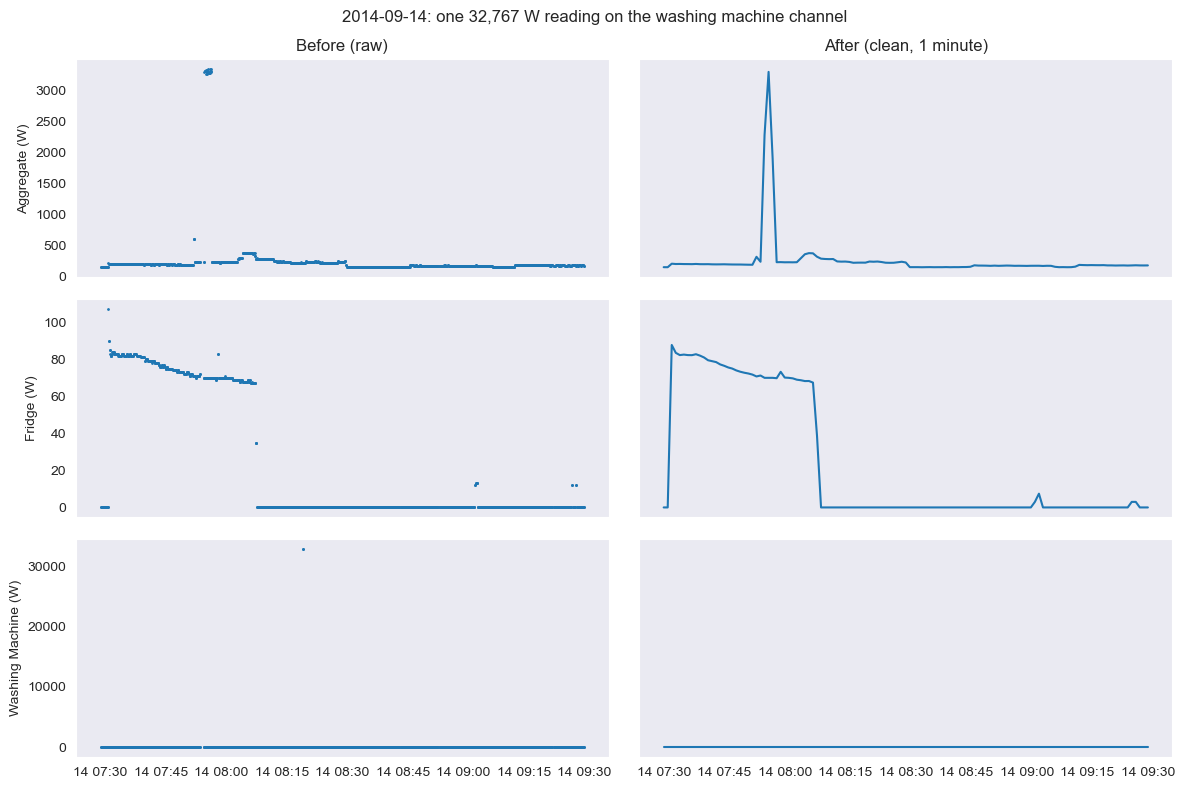

In [12]:
def before_after(start, end, title):
    inside = (t1 >= start) & (t1 <= end)                         # raw Part 1 rows in the window
    after = clean.loc[start:end]

    fig, axes = plt.subplots(3, 2, figsize=(12, 8), sharex=True, sharey="row")
    for row, c in enumerate(NAMES):
        axes[row, 0].plot(t1[inside], raw1.loc[inside, c], ".", markersize=2)
        axes[row, 1].plot(after.index, after[c])
        axes[row, 0].set_ylabel(NAMES[c] + " (W)")
    axes[0, 0].set_title("Before (raw)")
    axes[0, 1].set_title("After (clean, 1 minute)")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

before_after("2014-09-14 07:30", "2014-09-14 09:30", "2014-09-14: one 32,767 W reading on the washing machine channel")

<div style="background:#E9FBFA;border-left:4px solid #0FB9B1;padding:12px 18px;border-radius:0 6px 6px 0;margin:6px 0 16px 0;color:#12312F;"><span style="color:#0A6E68;">Before:</span> one washing machine reading of 32,767 W. <span style="color:#0A6E68;">After:</span> the reading is removed (the washing machine is at 0 W around it) and the aggregate and fridge keep their shape.</div>

**Example 2:** a long outage (Part 1). There are no raw readings for about 21 hours.

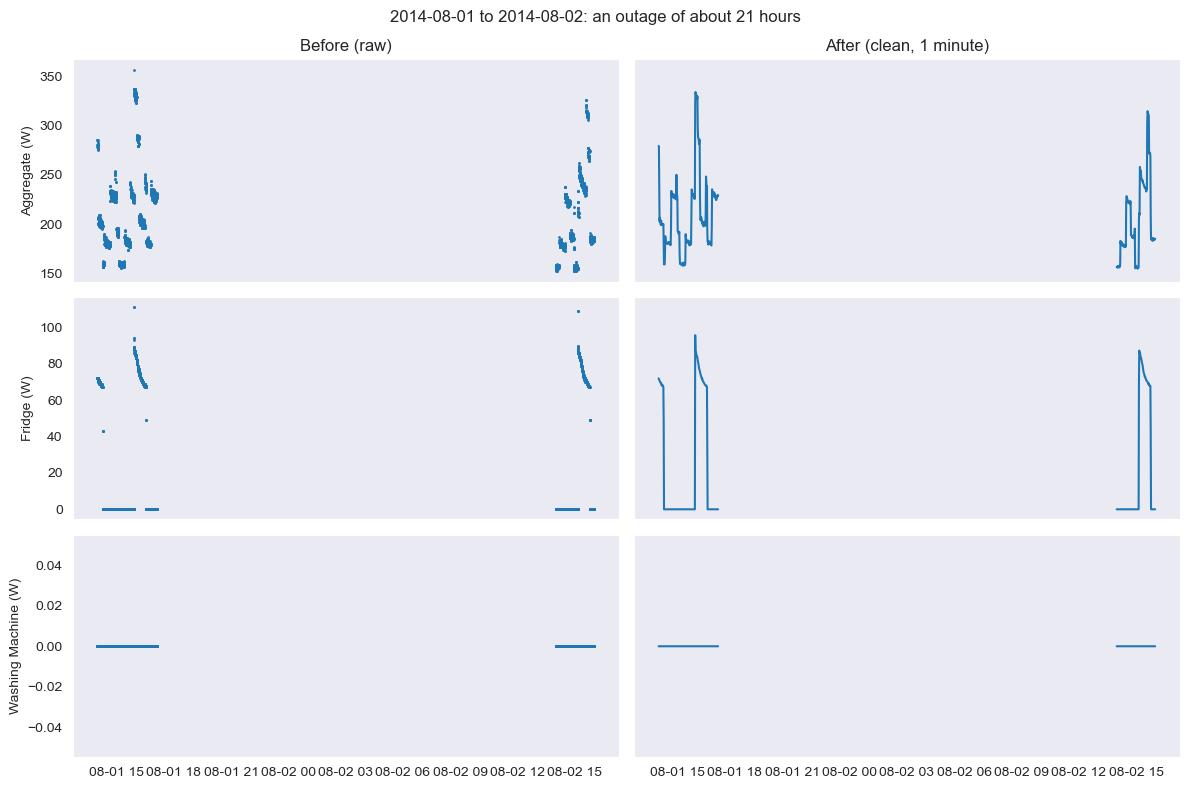

In [13]:
before_after("2014-08-01 14:00", "2014-08-02 16:00", "2014-08-01 to 2014-08-02: an outage of about 21 hours")

<div style="background:#E9FBFA;border-left:4px solid #0FB9B1;padding:12px 18px;border-radius:0 6px 6px 0;margin:6px 0 16px 0;color:#12312F;"><span style="color:#0A6E68;">Before:</span> the readings stop and restart. <span style="color:#0A6E68;">After:</span> the whole outage is a break in the line, because it is longer than 5 minutes it was <span style="color:#0A6E68;">not</span> filled (it carries <span style="color:#0A6E68;">gap = True</span>).</div>

<div style="background:linear-gradient(90deg,#0A6E68,#0FB9B1);padding:22px 28px;border-radius:10px;margin:18px 0 10px 0;"><h2 style="color:#ffffff;margin:0;font-weight:normal;">8. Conclusion and remaining data-quality limitations</h2></div>

<div style="background:#E9FBFA;border-left:4px solid #0FB9B1;padding:12px 18px;border-radius:0 6px 6px 0;margin:6px 0 16px 0;color:#12312F;"><span style="color:#0A6E68;">clean</span> has one row per minute for House 1 (2013-10-09 to 2015-07-10), a sorted, duplicate-free index and three flag columns (<span style="color:#0A6E68;">filled</span>, <span style="color:#0A6E68;">gap</span>, <span style="color:#0A6E68;">suspected_frozen</span>). The raw tables are unchanged.</div>

<div style="background:#E9FBFA;border-left:4px solid #0FB9B1;padding:12px 18px;border-radius:0 6px 6px 0;margin:6px 0 16px 0;color:#12312F;"><ul style="margin:6px 0 0 0;color:#12312F;"><li style="margin-bottom:4px;"><span style="color:#0A6E68;">Thresholds are judgement:</span> 4,000 W, 5 minutes and 30 minutes. A different choice would change the counts a little.</li>
<li style="margin-bottom:4px;"><span style="color:#0A6E68;">Suspected frozen readings are only flagged</span>, and only a stall that affects all channels and is exactly flat is caught. A single frozen sensor would not be detected.</li>
<li style="margin-bottom:4px;"><span style="color:#0A6E68;">Long outages</span> (flagged <span style="color:#0A6E68;">gap</span>) are not filled, so any analysis must handle the missing minutes. An appliance channel can be <span style="color:#0A6E68;">NaN</span> while the aggregate is present; the flags are based on the aggregate.</li>
<li style="margin-bottom:4px;"><span style="color:#0A6E68;">Part 1 uses 0 for "unavailable"</span>, so in Part 1 a <span style="color:#0A6E68;">0</span> can mean "off" or "missing". We cannot tell them apart.</li>
<li style="margin-bottom:4px;"><span style="color:#0A6E68;">The clock:</span> raw time is UK local time (daylight saving). I did not convert it. On 27 Oct 2013 the clock repeated one hour; sorting and deduplicating by timestamp mixes the readings from that hour. It is one hour in two years, so I accept it.</li>
<li style="margin-bottom:4px;"><span style="color:#0A6E68;">The aggregate is not capped.</span> A few extreme values (above 15 kW) are left in.</li></ul></div>